In [1]:
from models.CaloClouds_2 import CaloClouds_2
import torch
from torch.nn import Module

import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

In [2]:
from configs import Configs
cfg = Configs()
kdiffusion=True   # EDM vs DDPM diffusion
cfg.dropout_rate = 0.0
cfg.latent_dim = 0
cfg.residual = False

# new SF

In [3]:
import sys
sys.path.append('../point-cloud-diffusion/') # Henry's SF
# Simple shower configs for
# shower_flow_fixed_input_norms = True
# shower_flow_inputs = [ "cog_x", "cog_y", "clusters_per_layer", "energy_per_layer"]
# and
# shower_flow_num_blocks = 2

from pointcloud.config_varients import caloclouds_3_simple_shower
from pointcloud.utils import showerflow_utils
from pointcloud.models import shower_flow

configs = caloclouds_3_simple_shower.Configs()
# only if you are on a machine without CUDA
configs.device = "cpu"
# point to your events, because then functions that check the metadata check the right metadata
configs.dataset_path = "/data/dust/user/akorol/data/AngularShowers_RegularDetector/hdf5_for_CC/sim-E1261AT600AP180-180_file_{}slcio.hdf5"
configs.n_dataset_files = 88
# This lets you algorithmically get the input and conditioning dimensions. Then if we change them (taking out cog_z for example) you don't need to change other code.
cond_mask = showerflow_utils.get_cond_mask(configs)
input_mask = showerflow_utils.get_input_mask(configs)
# The version is the operations inside a block, you can also see it in the saved model name
version = "alt1"
constructor = shower_flow.versions_dict[version]
# Get ourselves an untrained model with the right architecture
flow_model, dist, flow_transforms = constructor(
    num_blocks=2,
    num_inputs=np.sum(input_mask),
    num_cond_inputs=np.sum(cond_mask),
    device=configs.device,
)
# load the weights
model_path = (
    "/data/dust/user/dayhallh/point-cloud-diffusion-data/showerFlow/sim-E1261AT600AP180-180/"
    "ShowerFlow_alt1_nb2_"  # block version and number of blocks
    "inputs8070450532247928831_"  # input mask representaiton
    "fnorms_best.pth"  # fnorms = Not normalising by layer with highest value, etc.
)
loaded = torch.load(model_path, map_location=configs.device)
flow_model.load_state_dict(loaded["model"])

<All keys matched successfully>

In [4]:
from pointcloud.utils.metadata import Metadata
mtd = Metadata(configs)

In [5]:
mtd

Metadata for /data/dust/user/akorol/data/AngularShowers_RegularDetector/hdf5_for_CC/sim-E1261AT600AP180-180_file_{}slcio.hdf5
layer_bottom_pos_hdf5: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29.]
half_cell_size_global: 2.5441665649414062
cell_thickness_global: 0.5250244140625
gun_xyz_pos_hdf5: [   0. 1811.    0.]
orientation: hdf5:xyz==local:xyz
gun_xyz_pos_global: [    0. 18047.   -50.]
orientation_global: hdf5:xyz==global:yzx
layer_bottom_pos_global: [1811.34020996 1814.46508789 1823.81005859 1826.93505859 1836.2800293
 1839.4050293  1848.75       1851.875      1861.2199707  1864.3449707
 1873.68994141 1876.81494141 1886.16003418 1889.28503418 1898.63000488
 1901.75500488 1911.09997559 1914.22497559 1923.56994629 1926.69494629
 1938.14001465 1943.36499023 1954.81005859 1960.03503418 1971.47998047
 1976.70495605 1988.15002441 1993.375      2004.81994629 2010.04504395]
Ymin_global: 1811
Xmin_global: -250
Xmax_g

# Trace SF


In [23]:
from pyro.nn import PyroModule, PyroSample
from pyro import poutine
import pyro.distributions as dist

device = torch.device('cpu')

flow_model.eval()
flow_model.requires_grad_(False)


class Flow_run(PyroModule):
    def __init__(self, flow_transforms, cond):
        super().__init__()
        self.base_dist = dist.Normal(torch.zeros(num_inputs).to(device), torch.ones(num_inputs).to(device))
        self.flow_dist = PyroSample(lambda self: dist.ConditionalTransformedDistribution(self.base_dist, flow_transforms).condition(cond).expand([1]).to_event(1))

    def forward(self):
        return self.flow_dist

cond_E = torch.FloatTensor(1, 1).uniform_(50, 50)
direction = torch.FloatTensor(1, 3).uniform_(0, 1)
context = torch.cat((cond_E, direction), 1)
num_inputs = 62

with torch.no_grad():
    pyro_trace = poutine.trace(Flow_run(flow_transforms, context)).get_trace()


class Container(Module):
    def __init__(self, model, pyro_trace, flow_transforms, num_inputs):
        super().__init__()
        self.model = model
        self.pyro_trace = pyro_trace
        self.flow_transforms = flow_transforms
        self.num_inputs = num_inputs

    def forward(self, cond):
        with torch.no_grad():
            pyro_replay = poutine.replay(self.model, self.pyro_trace)(self.flow_transforms, cond) #, self.batch_size)
            model_trace = poutine.trace(pyro_replay).get_trace()

            return model_trace.nodes["_RETURN"]['value']
        
traced_flow = Container(Flow_run, pyro_trace, flow_transforms, num_inputs) #, batch_size)
flow_module = torch.jit.trace_module(traced_flow, {"forward": context}, check_trace=True)

In [24]:
# quick check of the SF output
context = torch.tensor(
    [[0.572, 0.333, -0.4859, 0.808]]
) # some dummy context vector (E, direction_x, direction_y, direction_z)

samples = flow_module(context)[0].numpy()
print(samples.shape)
# oreder of 62 features
# CoG Y,
# CoG X,
# 30 points per layer
# 30 energies per layer

(62,)


# Inferer

In [10]:
class Inferrer(Module):
    def __init__(self, denoiser, shower_flow):
        super().__init__()
        
        self.energy_max = 127 # max energy of the dataset in GeV
        self.max_num_points = 7864 # dataset depended, max number of points in shower
        
        # In CC and CC2, the scale_factor for the total number of generated points in a shower
        # was energy-dependent (see occupancy calibration in Sec. 3.3 of CC).
        # Since no noticeable effect on physical properties was observed (e.g., di-photon energy,
        # resolution, or linearity), I decided to simplify this in CC3 to a single constant value.
        # One might consider extending it to be energy- and angle-dependent in the future.
        self.scale_factor = 0.64
        
        # max vis energy of the dataset
        self.vis_energy_max = 3.4 * 1000 # in MeV
        
        # CC and CC2 used slightly different normalization compared to CC3.
        # In CC and CC2, inputs were min-max scaled, while in CC3 they are standardized.
        # (No noticeable difference in physical performance was observed though, just filling of faster and more stable conversion.)
        # The values below were derived from a large portion of the training dataset.
        # The fidelity of di-photon, radial and energy profiles, and occupancy is quite sensitive to Xstd and Ystd,
        # so one might consider calibrating to improve performance.
        self.Xmean, self.Ymean, self.Zmean = -0.0074305227, -0.21205868, 12.359252
        self.Xstd, self.Ystd, self.Zstd = 22.4728036, 23.65837968, 5.305082

        # CC and CC2 had energies in GeV range while CC3 log scaled and standardized.
        # This numbers derived from traingin dataset
        self.Emean, self.Estd = -1.5300317, 1.2500798

        
        self.EIR = 1804.7 # ecal inner radius in mm from the IP
        self.layer_bottom_pos = torch.tensor([   1811.34020996, 1814.46508789, 1823.81005859, 1826.93505859,
                                                 1836.2800293 , 1839.4050293 , 1848.75      , 1851.875     ,
                                                 1861.2199707 , 1864.3449707 , 1873.68994141, 1876.81494141,
                                                 1886.16003418, 1889.28503418, 1898.63000488, 1901.75500488,
                                                 1911.09997559, 1914.22497559, 1923.56994629, 1926.69494629,
                                                 1938.14001465, 1943.36499023, 1954.81005859, 1960.03503418,
                                                 1971.47998047, 1976.70495605, 1988.15002441, 1993.375     ,
                                                 2004.81994629, 2010.04504395])
        self.layer_bottom_pos = self.layer_bottom_pos - self.EIR
        self.cell_thickness = 0.5250244140625 # in mm
        self.dist_to_layers = self.layer_bottom_pos + self.cell_thickness/2
        self.z_positions = torch.arange(30, dtype=torch.float) # just a layer number [0, 30)

        self.denoiser = denoiser
        self.shower_flow = shower_flow
        
        # CoG mean and std to rescale generated SF values back
        self.mean_cog = torch.tensor([-4.06743696e-03, -2.27790998e-01,  1.10137465e+01])
        self.std_cog = torch.tensor([1.24559791, 0.95357278, 2.59475371])

        # Energy scale factor to calibrate the total energy of the shower.
        # Derived from discrepancies in visible energy observed in a realistic detector
        # for 50 GeV showers.
        self.scale_energy = 1.00609194411797


    def get_direction(self, theta, phi):
    
        theta = theta/180. * torch.pi  # theta in radians
        phi = phi/180. * torch.pi  # phi in radians
        
        px = torch.cos( phi ) * torch.sin( theta ) 
        py = torch.sin( phi ) * torch.sin( theta )
        pz = torch.cos( theta ) 
        
        return torch.tensor([float(px.item()), float(py.item()), float(pz.item())])
    
    def get_shift(self, theta, phi, l: int):
                
        theta = theta/180. * torch.pi  # theta in radians
        phi = phi/180. * torch.pi  # phi in radians
        
        r = self.dist_to_layers[l] / torch.cos(theta)
        x_shift = r * torch.sin(theta) * torch.cos(phi)
        y_shift = r * torch.sin(theta) * torch.sin(phi)
        
        return x_shift, y_shift
    
    def get_cog(self, x,y,e):
        cog_x = torch.sum((x * e), dim=1) / e.sum(dim=1)
        cog_y = torch.sum((y * e), dim=1) / e.sum(dim=1)
        return cog_x, cog_y
    

    @torch.jit.script_method
    def forward(self, energy, theta, phi):
        """
        Args:
            energy:  Energy of the shower [MeV].
            theta:   Theta angle of the shower.
            phi:     Phi angle of the shower.
        Every input is in local coordinates.
        """
        
        cond_E = (energy / self.energy_max).view(1,1)
        direction = self.get_direction(theta, phi).unsqueeze(0)
        context = torch.cat((cond_E, direction), 1)
        
        with torch.no_grad():
            samples = self.shower_flow(context)
            
        cond_feats = context
                
        cog_x = samples[:, 0] * self.std_cog[0] + self.mean_cog[0]
        cog_y = samples[:, 1] * self.std_cog[1] + self.mean_cog[1]

        clusters_per_layer_cond = torch.clip(samples[:, 2:32], 0, None)  #  B,30
        clusters_per_layer_gen = torch.clip(samples[:, 2:32], 0, None) * self.max_num_points / 30 #  B,30
        e_per_layer_gen = torch.clip(samples[:, 32:], 0, None) * self.vis_energy_max / 30
        
        num_clusters = clusters_per_layer_gen.sum() * self.scale_factor
        clusters_per_layer_gen = (clusters_per_layer_gen / clusters_per_layer_gen.sum() * num_clusters).int()
        num_clusters = clusters_per_layer_gen.sum()

        with torch.no_grad():
            fake_shower = self.denoiser(cond_feats, num_clusters)
        
        z_flow = torch.repeat_interleave(self.z_positions, clusters_per_layer_gen[0], dim=0)
        idx_dm = torch.argsort(fake_shower[0, :, 2])
        fake_shower[0, :, 2][idx_dm] = z_flow
        
        # renormilize
        fake_shower[:, :, 0] = fake_shower[:, :, 0]*self.Xstd*2 + self.Xmean
        fake_shower[:, :, 1] = fake_shower[:, :, 1]*self.Ystd*2 + self.Ymean
        fake_shower[:, :, 3] = torch.exp(fake_shower[:, :, 3]*self.Estd*2 + self.Emean)
        
        # cog calibration
        cog = self.get_cog(fake_shower[:, :, 0], fake_shower[:, :, 1], fake_shower[:, :, 3])
        fake_shower[:, :, 0] = fake_shower[:, :, 0] - (cog[0] - cog_x).unsqueeze(1)
        fake_shower[:, :, 1] = fake_shower[:, :, 1] - (cog[1] - cog_y).unsqueeze(1)
        
        # energy per layer calibration
        for j in range(len(self.z_positions)):
            mask = fake_shower[0, :, 2] == self.z_positions[j]
            fake_shower[0, :, -1][mask] = fake_shower[0, :, -1][mask] / fake_shower[0, :, -1][mask].sum() * e_per_layer_gen[0, j]
            
            x_shift, y_shift = self.get_shift(theta, phi, j)
            fake_shower[0, :, 0][mask] = (fake_shower[0, :, 0][mask] + x_shift).view(-1)
            fake_shower[0, :, 1][mask] = (fake_shower[0, :, 1][mask] + y_shift).view(-1)


        # total energy calibration
        fake_shower[:, :, 3] = fake_shower[:, :, 3] * self.scale_energy 

        fake_shower = fake_shower[0].view(-1)
        fake_shower = torch.concat((clusters_per_layer_gen.view(-1), fake_shower))
        
        return fake_shower

In [11]:

from models.common import *
from utils.misc import *

import k_diffusion as K

device = torch.device("cpu")

class CaloClouds_2(Module):

    def __init__(self,):
        super(CaloClouds_2, self).__init__()
        
        self.features = 4
        self.sigma_max = 80 # from configs.py
        
        net = PointwiseNet_kDiffusion(
            point_dim=4, # from configs.py
            context_dim=4 # from configs.py
        )
        
        self.diffusion = Denoiser(
            net,
            sigma_data = 0.5, # from configs.py
            device=device, # from configs.py
            sigma_min=0.002 # from configs.py
        )
    
    @torch.jit.script_method
    def forward(self, cond_feats, num_points: int):

        z = cond_feats  

        x_T = torch.randn([z.size(0), num_points, self.features], device=z.device) * self.sigma_max
        
        x_0 = self.diffusion.forward(x_T, self.sigma_max, context=z)

        return x_0


class Denoiser(Module):
    """A Karras et al. preconditioner for denoising diffusion models."""

    def __init__(self, inner_model, sigma_data=0.5, device='cpu', sigma_min = 0.002):
        super(Denoiser, self).__init__()
        self.inner_model = inner_model
        
        sigma_data = [sigma_data, sigma_data, sigma_data, sigma_data]
        self.sigma_data = torch.tensor(sigma_data, device=device)   # 4,
        self.sigma_min = sigma_min
    
    def get_scalings_for_boundary_condition(self, sigma):   # B,   # for consistency model
        sigma_data = self.sigma_data.expand(sigma.shape[0], -1)   # B, 4
    
        c_skip = sigma_data**2 / (
            (sigma - self.sigma_min) ** 2 + sigma_data**2
        )   # B, 4
        c_out = (
            (sigma - self.sigma_min)
            * sigma_data
            / (sigma**2 + sigma_data**2) ** 0.5
        )   # B, 4
        c_in = 1 / (sigma ** 2 + sigma_data ** 2) ** 0.5  # B, 4
        return c_skip, c_out, c_in
    
    
    @torch.jit.script_method
    def forward(self, input, sigma: int, context):   # same as "denoise" in KarrasDenoiser of CM code
        
        sigma = (
            torch.tensor([sigma] * input.shape[0], dtype=torch.float32)
            .to(input.device)
            .unsqueeze(1)
        )
        
        c_skip, c_out, c_in = [x.unsqueeze(1) for x in self.get_scalings_for_boundary_condition(sigma)]
        

        return self.inner_model(input * c_in, sigma, context) * c_out + input * c_skip
    



class PointwiseNet_kDiffusion(Module):

    def __init__(self, point_dim, context_dim):
        super(PointwiseNet_kDiffusion, self).__init__()
        time_dim = 64
        fourier_scale = 16   # 1 in k-diffusion, 16 in EDM, 30 in Score-based generative modeling

        self.act = F.leaky_relu
        
        # CC and CC2 Point Wise Net
        # self.layers = ModuleList([
        #     ConcatSquashLinear(point_dim, 128, context_dim+time_dim),
        #     ConcatSquashLinear(128, 256, context_dim+time_dim),
        #     ConcatSquashLinear(256, 512, context_dim+time_dim),
        #     ConcatSquashLinear(512, 256, context_dim+time_dim),
        #     ConcatSquashLinear(256, 128, context_dim+time_dim),
        #     ConcatSquashLinear(128, point_dim, context_dim+time_dim)
        # ])

        # CC3 Point Wise Net
        self.layers = ModuleList([
            ConcatSquashLinear(point_dim, 32, context_dim+time_dim),
            ConcatSquashLinear(32, 64, context_dim+time_dim),
            ConcatSquashLinear(64, 128, context_dim+time_dim),
            ConcatSquashLinear(128, 64, context_dim+time_dim),
            ConcatSquashLinear(64, 32, context_dim+time_dim),
            ConcatSquashLinear(32, point_dim, context_dim+time_dim)
        ])

        self.timestep_embed = nn.Sequential(
            K.layers.FourierFeatures(1, time_dim, std=fourier_scale),   # 1D Fourier features --> with register_buffer, so weights are not trained
            nn.Linear(time_dim, time_dim), # this is a trainable layer
        )
    
    @torch.jit.script_method
    def forward(self, x: torch.Tensor, sigma: torch.Tensor, context: torch.Tensor): # inportant to spesify datatypes
        """
        Args:
            x:  Point clouds at some timestep t, (B, N, d).
            sigma:     Time. (B, ).  --> becomes "sigma" in k-diffusion
            context:  Shape latents. (B, F). 
        """
        batch_size = x.size(0)
        sigma = sigma.view(batch_size, 1, 1)          # (B, 1, 1)
        context = context.view(batch_size, 1, -1)   # (B, 1, F)

        # formulation from EDM paper / k-diffusion
        c_noise = sigma.log() / 4  # (B, 1, 1)
        time_emb = self.act(self.timestep_embed(c_noise))  # (B, 1, T)
        
        # time_emb = torch.cat([beta, torch.sin(beta), torch.cos(beta)], dim=-1)  # (B, 1, 3)
        ctx_emb = torch.cat([time_emb, context], dim=-1)    # (B, 1, F+T)   # TODO: might want to add additional linear embedding net for context or only cond_feats

        out = x
        for i, layer in enumerate(self.layers):
            out = layer(ctx=ctx_emb, x=out)
            if i < len(self.layers) - 1:
                out = self.act(out)
        
        return out


class ConcatSquashLinear(Module):
    def __init__(self, dim_in, dim_out, dim_ctx):
        super(ConcatSquashLinear, self).__init__()
        self._layer = Linear(dim_in, dim_out)
        self._hyper_bias = Linear(dim_ctx, dim_out, bias=False)
        self._hyper_gate = Linear(dim_ctx, dim_out)
    
    @torch.jit.script_method
    def forward(self, ctx, x):
        gate = torch.sigmoid(self._hyper_gate(ctx))
        bias = self._hyper_bias(ctx)
        ret = self._layer(x) * gate + bias
        return ret

In [12]:
cfg.logdir = '/data/dust/user/akorol/beegfs.migration/logs/point-clouds'
checkpoint = torch.load(f'{cfg.logdir}/CaloClouds3_CD_small_2025_01_07__08_26_02/ckpt_0.000000_6135000.pt', map_location=torch.device('cpu'))   # max 1200000


model = CaloClouds_2().to(torch.device('cpu'))
model.load_state_dict(checkpoint['others']['model_ema'])
model.eval()

CaloClouds_2(
  (diffusion): Denoiser(
    (inner_model): PointwiseNet_kDiffusion(
      (layers): ModuleList(
        (0): ConcatSquashLinear(
          (_layer): Linear(in_features=4, out_features=32, bias=True)
          (_hyper_bias): Linear(in_features=68, out_features=32, bias=False)
          (_hyper_gate): Linear(in_features=68, out_features=32, bias=True)
        )
        (1): ConcatSquashLinear(
          (_layer): Linear(in_features=32, out_features=64, bias=True)
          (_hyper_bias): Linear(in_features=68, out_features=64, bias=False)
          (_hyper_gate): Linear(in_features=68, out_features=64, bias=True)
        )
        (2): ConcatSquashLinear(
          (_layer): Linear(in_features=64, out_features=128, bias=True)
          (_hyper_bias): Linear(in_features=68, out_features=128, bias=False)
          (_hyper_gate): Linear(in_features=68, out_features=128, bias=True)
        )
        (3): ConcatSquashLinear(
          (_layer): Linear(in_features=128, out_featu

In [14]:
inferrer = Inferrer(model, flow_module)

In [15]:
path_to_save = 'chpt.pt'
CC2_container = torch.jit.script(inferrer)
torch.jit.save(CC2_container, path_to_save)

# Load and tests

In [16]:
CC2_container_full_load = torch.jit.load(path_to_save)

In [17]:
%%timeit
fake_shower = CC2_container_full_load(torch.tensor(50), torch.tensor(0), torch.tensor(0))

21.4 ms ± 579 µs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [18]:
fake_showers = []
for i in tqdm(range(300)):
    fake_shower = CC2_container_full_load(torch.tensor(50), torch.tensor(0), torch.tensor(0))
    fake_shower = fake_shower.numpy()
    x = fake_shower[30::4]
    y = fake_shower[31::4]
    z = fake_shower[32::4]
    e = fake_shower[33::4]

    x = np.concatenate( ( x, np.zeros(4500 - len(x)) ) )
    y = np.concatenate( ( y, np.zeros(4500 - len(y)) ) )
    z = np.concatenate( ( z, np.zeros(4500 - len(z)) ) )
    e = np.concatenate( ( e, np.zeros(4500 - len(e)) ) )

    fake_shower = np.asarray([x,y,z,e])
    fake_showers.append(fake_shower)
fake_showers = np.asarray(fake_showers)

100%|██████████| 300/300 [00:06<00:00, 43.01it/s]


In [26]:
x = fake_showers[:, 0, :].reshape(-1)
y = fake_showers[:, 1, :].reshape(-1)
z = fake_showers[:, 2, :].reshape(-1)
e = fake_showers[:, 3, :].reshape(-1)


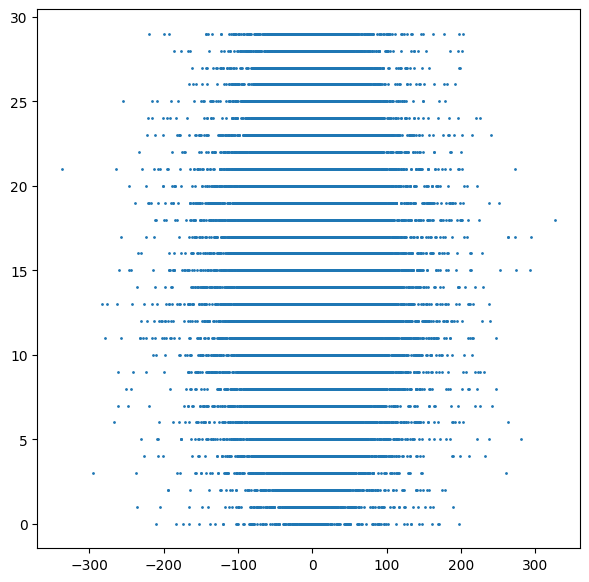

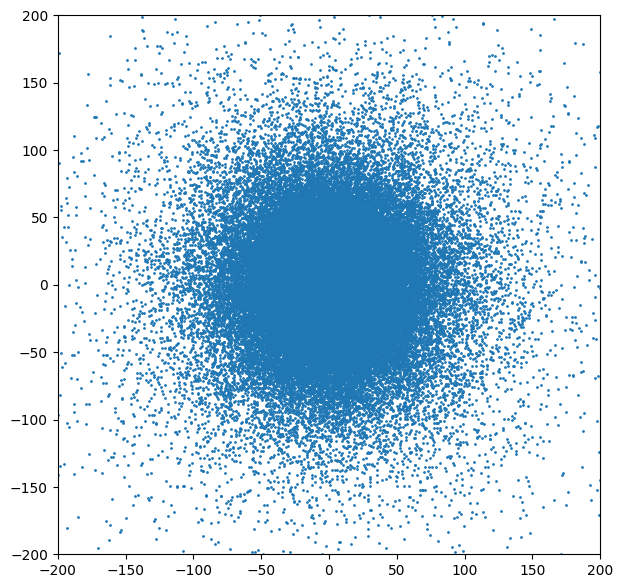

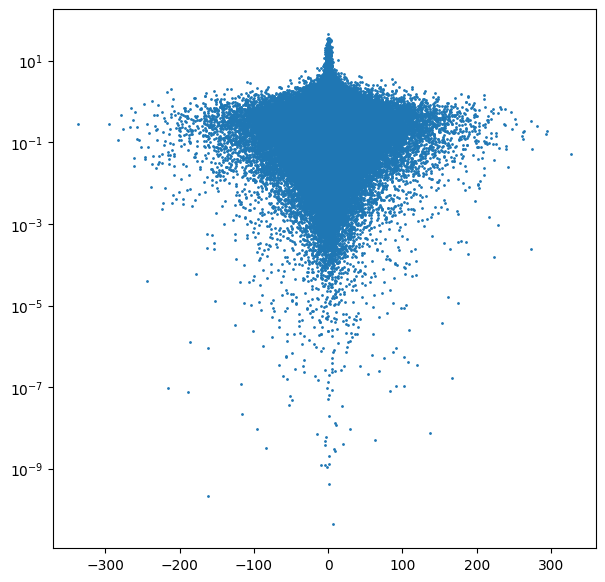

In [27]:
plt.figure(figsize=(7,7))
plt.scatter(x[:],z[:], s=1)
plt.show()
plt.figure(figsize=(7,7))
plt.scatter(x[:],y[:], s=1)
plt.xlim(-200, 200)
plt.ylim(-200, 200)
plt.show()
plt.figure(figsize=(7,7))
plt.scatter(x[:],e[:], s=1)
plt.yscale('log')
plt.show()


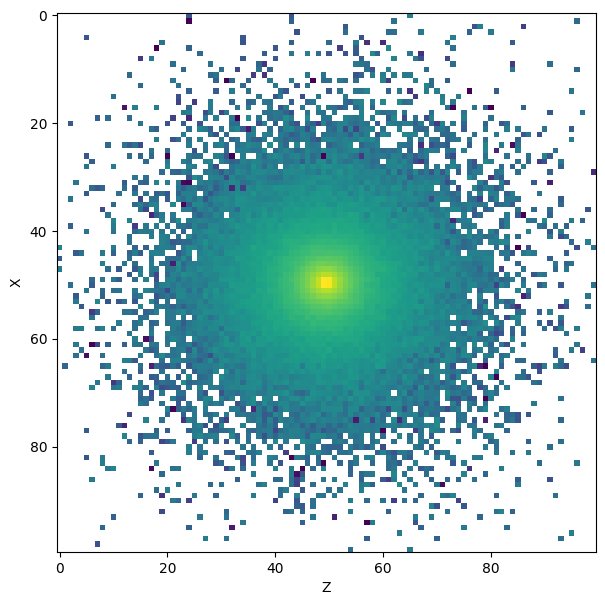

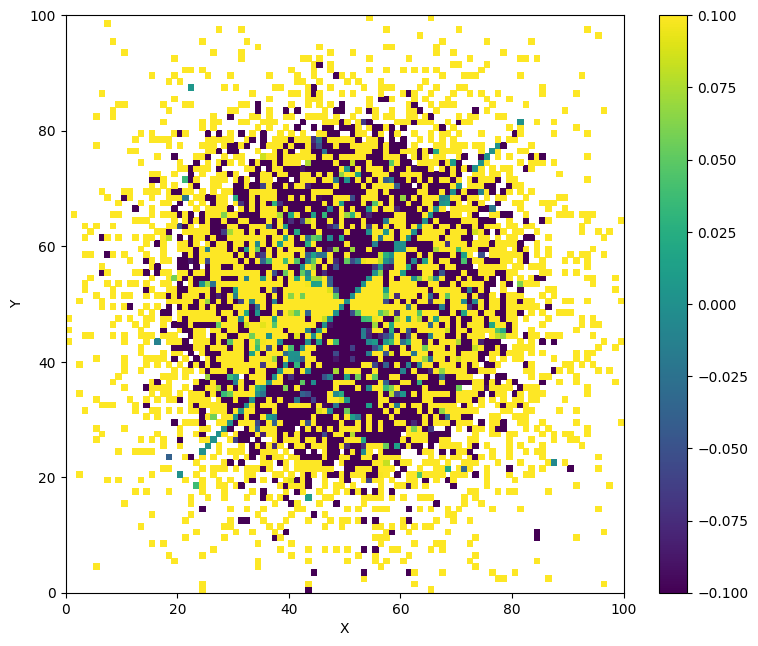

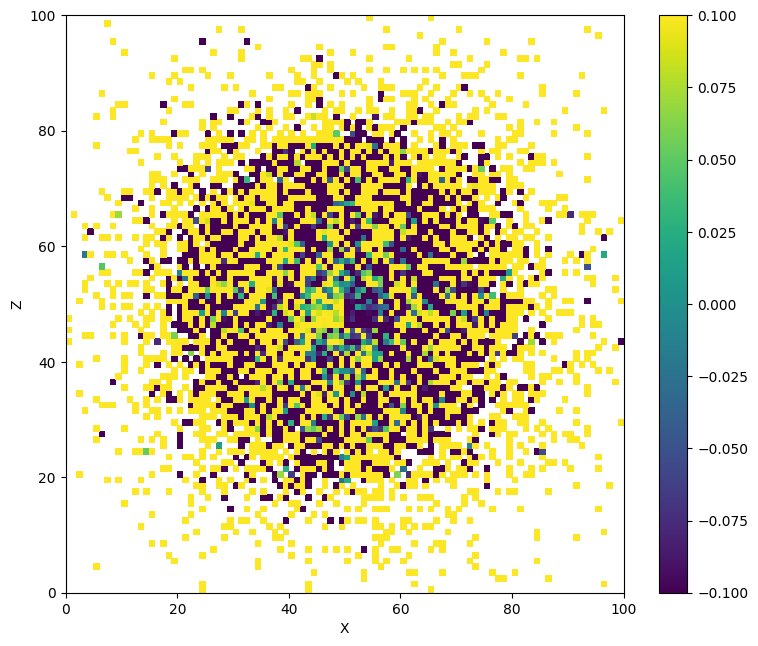

In [28]:
import matplotlib

H, _, _ = np.histogram2d(x, y, range=((-250,250), (-250,250)), bins=(100, 100), weights=e)
H[H < 0] = 0

plt.figure(figsize=(7,7))
plt.imshow(H[:, :], norm=matplotlib.colors.LogNorm(vmin=H[H>0].min()*1e6, vmax=H.max()))
plt.xlabel('Z')
plt.ylabel('X')
plt.show()

plt.figure(figsize=(9,7.5))
plt.pcolor((H-H.T)/H, vmin=-0.1, vmax=0.1)
plt.colorbar()
plt.xlabel('X')
plt.ylabel('Y')
plt.show()
plt.figure(figsize=(9,7.5))
plt.pcolor((H-H[:, ::-1])/H, vmin=-0.1, vmax=0.1)
plt.colorbar()
plt.xlabel('X')
plt.ylabel('Z')
plt.show()

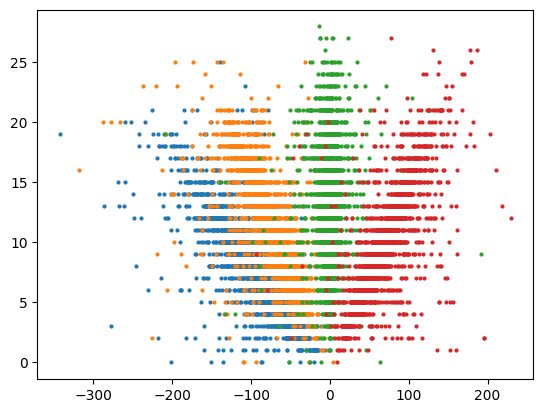

In [29]:
thetas = [-60, -45, 0, 45]

for theta in thetas:
    fake_shower = CC2_container_full_load(torch.tensor(50), torch.tensor(theta), torch.tensor(0))
    fake_shower = fake_shower.numpy()
    x = fake_shower[30::4]
    y = fake_shower[31::4]
    z = fake_shower[32::4]
    e = fake_shower[33::4]

    plt.scatter(x, z, s=4)
    
plt.show()